# Bahrain rental prediction — completed workflow
Predict `rent`; evaluate **MAE in Bahraini dinars** on the original rent scale. This companion notebook preserves the original notebook. Run all cells in order; update DATA_DIR when moving it.

## Audit of work marked done
EDA was partially complete: types, categories and missingness were inspected; distributions, target extremes, duplicates and subgroup evaluation were missing. Area cleaning was largely complete; retained sqm extraction and added sqft conversion and invalid-value handling. The original model used only area and an unseeded split.

Removed the unsupported rule that infers bedrooms from bathrooms. Studios remain zero bedrooms. Preserve detailed property types rather than treating compounds/penthouses as apartments. Retain Central Governorate as a source label: moving all Central records to Southern needs verified location-level evidence.

This workflow adds deterministic cleaning, training-only preprocessing, encoding explanations, grouped splits, seven model benchmarks plus a blend, MAE and final prediction export.

**Pending your input:** a verified city/village mapping. The nullable binary column is created but excluded from fitting until a mapping is supplied. No neighborhoods or islands are guessed to be cities/villages. Results below are the baseline **without this pending feature**.

## Results from the executed run
**Selected model: Histogram boosting MAE.** Final grouped holdout MAE: **136.84 BHD**, versus **281.42 BHD** for the median baseline (51.4% lower MAE). Validation MAE was 147.69 BHD. The equal-weight blend was worse at 151.06 BHD.

The final holdout has 6,409 rows. These are local holdout results, not competition leaderboard scores. All extreme labels remain in the main MAE. Training MAE is higher than validation MAE here; the partitions contain different extreme-rent tails, so this gap alone does not establish underfitting or overfitting.

Training area skewness was 7.78 before log1p and -0.98 afterward. This supports compressing area for linear models, but does not establish normality. Scaling is justified by comparable coefficient scales and Ridge regularization, not a normality requirement.

City/village is still pending your verified mapping. Predictions for all 3,566 competition rows were generated, but the sample/test identifier mismatch must be resolved before submission. The original notebook was not modified.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor, VotingRegressor
from sklearn.metrics import mean_absolute_error
SEED=42
DATA_DIR=Path(r'C:\Users\TALAL ALOTHMAN\Documents\GitHub\test-github\Competetion')
OUTPUT_DIR=Path.cwd()
raw=pd.read_csv(DATA_DIR/'property_data.csv')
external=pd.read_csv(DATA_DIR/'test.csv')
sample=pd.read_csv(DATA_DIR/'sample_submission.csv')
print('Training data:',raw.shape,'Competition test:',external.shape)
assert 'rent' not in external
print('Dependencies: pandas, numpy, matplotlib, seaborn, scikit-learn >= 1.2')

Training data: (32090, 41) Competition test: (3566, 40)
Dependencies: pandas, numpy, matplotlib, seaborn, scikit-learn >= 1.2


## 1. Cleaning without learned statistics
All rules below are deterministic and use no target. Learned medians, scaling and category vocabularies are fitted later inside pipelines.

* **Location:** explicit city first; otherwise recover the second component of governorate, then the penultimate component of location_full (two or more parts), then the final component of area. This city column represents source city/locality labels, including neighborhoods. Inspect recovered examples; this is source-text recovery, not external geographic verification. Lowercase/trim labels; keep missing places Unknown.
* **Rooms:** studio = 0, `4+ Maid` = 4 main bedrooms, `7+` = 7 lower bound. Preserve maid/top-coded flags. Land, Whole Building and Bulk Rent Unit have zero placeholders plus a rooms-applicable flag; other missing rooms receive fitted medians plus missingness flags. Structural zeros are placeholders, not claims about building totals.
* **Area:** prefer sqm in mixed-unit text, convert sqft-only values using 0.09290304, reject nonpositive/nonfinite values. Do not silently remove large valid properties.
* **Utilities:** inclusive = 1; missing, notSelected and exclusive = 0 per your instruction.
* **Furnishing:** missing/NO = 1, PARTLY = 2, YES = 3. Unknown labels are audited below. Missing means unfurnished by your assumption, not verified fact.
* **Agent:** a meaningful agency name or positive agent/broker ID means 1. Zero means no recorded evidence, not proof of private ownership. Descriptions, titles and price_per_sqm are excluded because they can contain rent-derived information.

In [2]:
# Supply verified normalized location names -> 1 (city) or 0 (village).
CITY_VILLAGE={}
def text_col(frame,col):
    s=frame[col] if col in frame else pd.Series(pd.NA,index=frame.index)
    s=s.astype('string').str.strip().str.replace(r'\s+',' ',regex=True)
    return s.mask(s.str.lower().isin(['','none','null','nan','n/a','notselected']))
def clean_features(frame):
    x=pd.DataFrame(index=frame.index)
    p=text_col(frame,'property_type').str.lower()
    x['property_type']=p.replace({'short term & hotel apartment':'hotel apartment'}).fillna('unknown')
    gov=text_col(frame,'governorate')
    x['governorate']=gov.str.split(',').str[0].str.strip().str.lower().fillna('unknown')
    city=text_col(frame,'city')
    gov_city=gov.str.split(',').str[1].str.strip()
    full=text_col(frame,'location_full').str.split(',')
    full_city=full.map(lambda v:v[-2].strip() if isinstance(v,list) and len(v)>=2 else pd.NA).astype('string')
    area_city=text_col(frame,'area').str.split(',').str[-1].str.strip()
    city=city.fillna(gov_city).fillna(full_city).fillna(area_city).str.lower()
    x['city']=city.fillna('unknown')
    x['city or vallige']=city.map(CITY_VILLAGE).astype(float)
    applicable=~p.isin(['land','whole building','bulk rent unit'])
    x['rooms_applicable']=applicable.astype(int)
    for col in ['bedrooms','bathrooms']:
        s=text_col(frame,col).str.lower()
        v=pd.to_numeric(s.str.extract(r'(-?\d+(?:\.\d+)?)',expand=False),errors='coerce')
        if col=='bedrooms':
            v=v.mask(s.str.contains('studio',na=False),0)
            x['bedrooms_has_maid']=(s.str.contains('maid',na=False)&applicable).astype(int)
        x[col+'_topcoded']=(s.str.contains(r'^\d+\+(?!\s*maid)',na=False)&applicable).astype(int)
        x[col+'_missing']=(v.isna()&applicable).astype(int)
        x[col]=v.where(v.ge(0)).where(applicable,0).astype(float)
    area=text_col(frame,'area_sqm').str.replace(',','',regex=False).str.lower()
    sqm=pd.to_numeric(area.str.extract(r'(-?\d+(?:\.\d+)?)\s*(?:sqm|sq\.?\s*m|m2|m²)\b',expand=False),errors='coerce')
    sqft=pd.to_numeric(area.str.extract(r'(-?\d+(?:\.\d+)?)\s*(?:sqft|sq\.?\s*ft)\b',expand=False),errors='coerce')
    a=sqm.astype(float).fillna(sqft.astype(float)*.09290304).fillna(pd.to_numeric(area,errors='coerce'))
    x['area_sqm']=a.where(a.gt(0)&np.isfinite(a)).astype(float)
    x['area_sqm_missing']=x.area_sqm.isna().astype(int)
    x['include_w_e']=text_col(frame,'include_w_e').str.lower().eq('inclusive').fillna(False).astype(int)
    x['furnished']=text_col(frame,'furnished').str.lower().map({'no':1,'yes':3,'partly':2,'unfurnished':1,'furnished':3,'partially furnished':2}).fillna(1).astype(int)
    agency=text_col(frame,'agency')
    has_agency=agency.notna()&~agency.str.lower().isin(['0','no','false','private','owner'])
    agent=pd.to_numeric(text_col(frame,'agent_id'),errors='coerce').gt(0)
    broker=pd.to_numeric(text_col(frame,'broker_id'),errors='coerce').gt(0)
    x['has_agent']=(has_agency|agent|broker).fillna(False).astype(int)
    return x
X=clean_features(raw)
y=pd.to_numeric(raw.rent,errors='coerce')
assert y.notna().all() and np.isfinite(y).all() and y.gt(0).all()
assert set(CITY_VILLAGE.values()).issubset({0,1})
display(pd.DataFrame({'raw_missing_pct':raw.reindex(columns=X.columns).isna().mean()*100,'clean_missing_pct':X.isna().mean()*100}).round(2))
for c in ['include_w_e','furnished','period']:
    display(raw[c].value_counts(dropna=False).rename(c).to_frame())
display(pd.concat([raw[['city','governorate','location_full']].add_prefix('source_'),X[['city']]],axis=1).head(12))
print('Duplicate IDs:',raw.Property_id.duplicated().sum(),'Duplicate nonmissing URLs:',raw.URL.dropna().duplicated().sum())

,raw_missing_pct,clean_missing_pct
property_type,0.00,0.00
governorate,0.00,0.00
city,74.43,0.00
city or vallige,100.00,100.00
rooms_applicable,100.00,0.00
bedrooms_has_maid,100.00,0.00
bedrooms_topcoded,100.00,0.00
bedrooms_missing,100.00,0.00
bedrooms,0.04,0.01
bathrooms_topcoded,100.00,0.00


,include_w_e
include_w_e,
inclusive,9448
NaN,8206
Inclusive,5834
notSelected,4809
Exclusive,3692
exclusive,101


,furnished
furnished,
NaN,17746
YES,10090
PARTLY,3339
NO,915


,period
period,
NaN,17732
monthly,14358


,source_city,source_governorate,source_location_full,city
0,NaN,"Capital Governorate, Manama","Sanabis, Manama, Capital Governorate",manama
1,NaN,Capital Governorate,NaN,al juffair
2,NaN,Northern Governorate,NaN,hamala
3,NaN,Capital Governorate,"Seef, Capital Governorate",seef
4,Amwaj Islands,Muharraq Governorate,NaN,amwaj islands
5,Busaiteen,Muharraq Governorate,NaN,busaiteen
6,Dilmunia Island,Muharraq Governorate,NaN,dilmunia island
7,NaN,Northern Governorate,"Janabiya, Northern Governorate",janabiya
8,NaN,Capital Governorate,NaN,seef
9,NaN,Muharraq Governorate,"Busaiteen, Muharraq Governorate",busaiteen


Duplicate IDs: 0 Duplicate nonmissing URLs: 566


## 2. Leakage-aware split before EDA-driven choices
Approximately 60% fitting, 20% validation, 20% final test. Connected components keep shared IDs, URLs, or identical cleaned feature signatures together. Feature grouping is deliberately conservative: separate real properties can have identical attributes. It guards against interchangeable records crossing partitions, but does not detect every near-duplicate advertisement. This evaluates grouped random generalization, not future-time forecasting.

Rent is continuous, so classification balancing/SMOTE is inappropriate. Preserve the natural rent mix, use absolute-error objectives where practical, and report subgroup counts and MAE. Rare property types can have uncertain or absent estimates. Do not delete or clip target outliers without source verification.

In [3]:
parent=np.arange(len(X))
def root(i):
    while parent[i]!=i:
        parent[i]=parent[parent[i]]
        i=parent[i]
    return i
signature=pd.util.hash_pandas_object(X.astype(str),index=False)
for key in [signature,text_col(raw,'Property_id'),text_col(raw,'URL')]:
    seen={}
    for i,value in enumerate(key):
        if pd.isna(value): continue
        if value in seen: parent[root(i)]=root(seen[value])
        else: seen[value]=i
groups=np.array([root(i) for i in range(len(X))])
dev,test_idx=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED).split(X,y,groups))
a,b=next(GroupShuffleSplit(n_splits=1,test_size=.25,random_state=SEED+1).split(X.iloc[dev],y.iloc[dev],groups[dev]))
train_idx,val_idx=dev[a],dev[b]
assert not(set(groups[train_idx])&set(groups[val_idx]))
assert not(set(groups[dev])&set(groups[test_idx]))
print('Rows fit/validation/test:',len(train_idx),len(val_idx),len(test_idx),'Groups:',len(set(groups)))
partition=pd.Series(np.select([X.index.isin(train_idx),X.index.isin(val_idx)],['fit','validation'],default='test'),index=X.index)
display(pd.crosstab(X.property_type,partition))

Rows fit/validation/test: 19596 6085 6409 Groups: 13634


col_0,fit,test,validation
property_type,,,
apartment,15363,5000,4653
bulk rent unit,6,4,2
bungalow,1,2,0
chalet,2,0,0
compound,193,96,61
duplex,176,51,65
hotel apartment,23,3,2
land,3,1,0
penthouse,113,31,38


## 3. Training-only plots and feature-engineering justification
**Nominal columns:** property_type, governorate and city are one-hot encoded, avoiding arbitrary numeric order. Categories with fewer than 20 training rows are pooled; unseen values are handled by the encoder. City/governorate can be correlated, motivating a regularized linear benchmark.

**Area:** plot raw and log1p distributions below. Log1p compresses multiplicative differences and skew for the linear branch. **StandardScaler does not require normally distributed features** and does not make them normal. It puts linear numeric coefficients on comparable scales, useful for Ridge's penalty. Trees use raw units and require no scaling.

**Rooms:** retain numeric counts and companion applicability, missingness and maid/top-code flags. Median imputation is fitted only on training rows; distributions show discreteness and skew, not a reason to force normality.

**Furnishing:** ordinal 1/2/3 for trees, which can learn different threshold effects; one-hot for linear models, avoiding an assumed equal rent increase per step. **Utilities/agent/flags:** already binary, passed through unchanged. Pending city/village will be binary with imputation and an unknown indicator once a mapping is available.

Axis-limited histograms are explicitly labeled: all observations remain in training and MAE. Target is not log-transformed, since log-error optimization differs from dinar MAE.

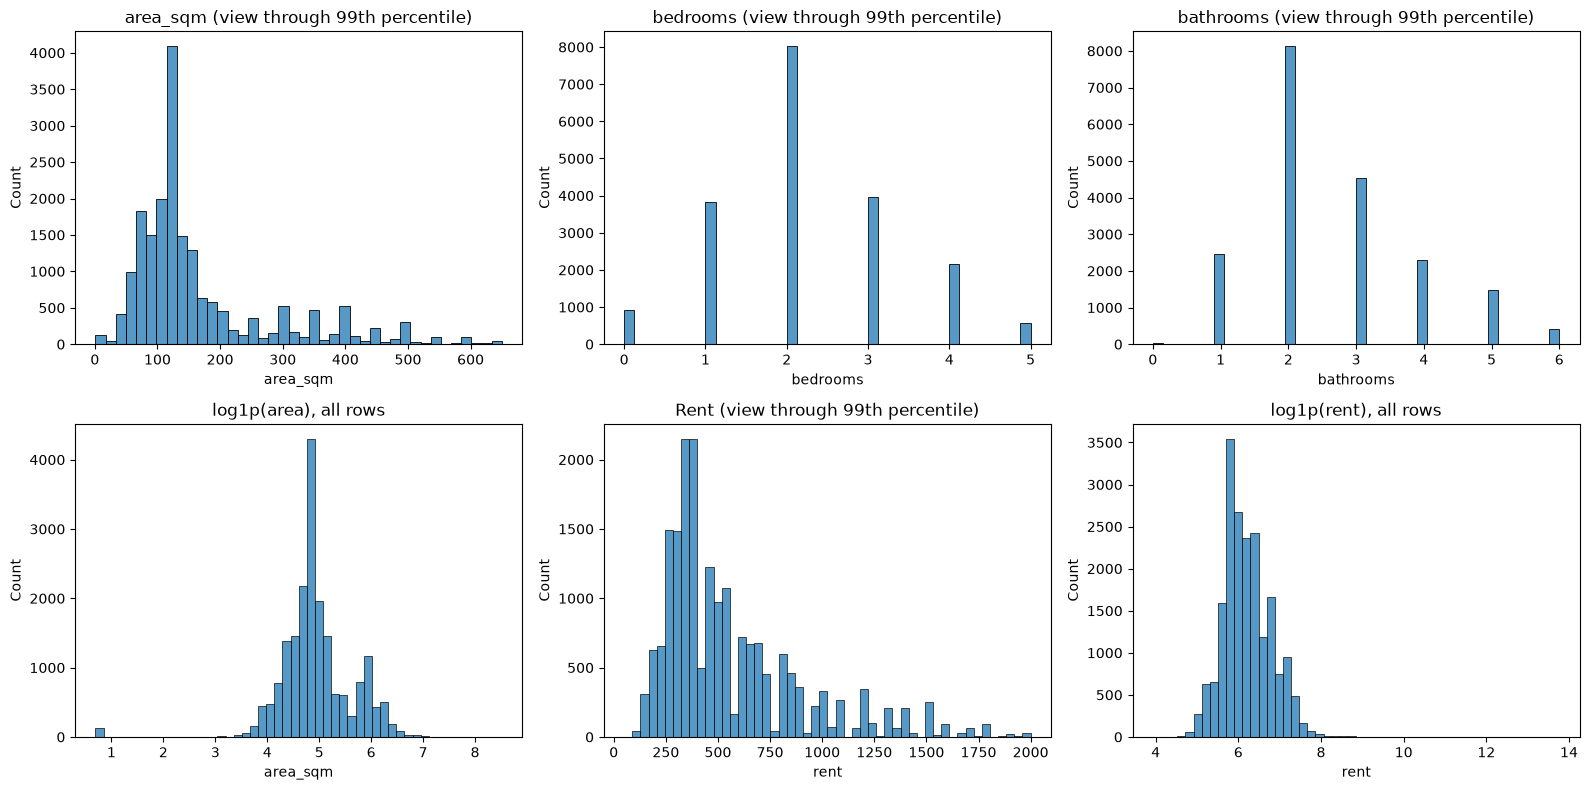

,raw_area_skew,log_area_skew
0,7.784759,-0.980693


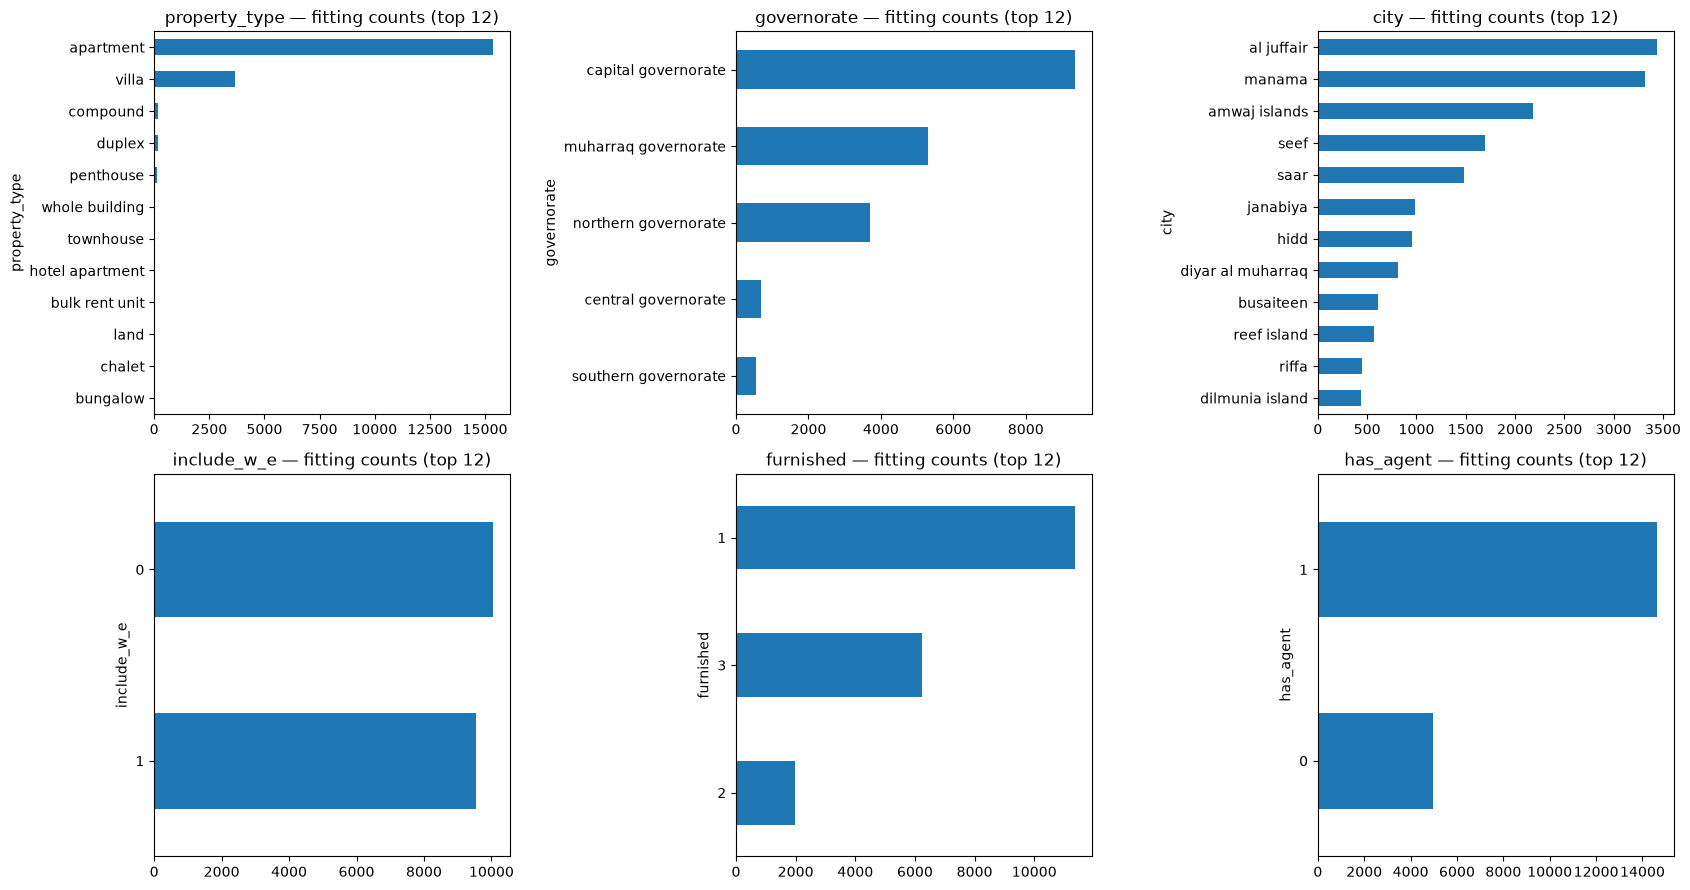

,fit rent
count,19596.000000
mean,748.944019
std,8426.431454
min,50.000000
1%,150.000000
50%,450.000000
90%,1100.000000
95%,1400.000000
99%,2000.000000
99.9%,37858.000000


,Property_id,property_type,rent,area_sqm,period
16545,4f24c9cc-e14a-49df-b4c9-165c4e09a464,Apartment,950000.0,186.0,monthly
3795,e63d2b33-4a93-4db7-aaa2-e9c22892dc02,Villa,400000.0,545.0,monthly
23435,68ba51f2-fe88-4a50-8051-d7309543bdf3,Villa,400000.0,"5,866 sqft / 545 sqm",NaN
16257,7e9f4e7d-3029-406c-bb9c-81c712836405,Villa,160000.0,260.0,monthly
16174,6ca551b0-9c9a-4bd8-bc31-a42501e744a4,Villa,146500.0,"4,844 sqft / 450 sqm",NaN
3360,f9dd1a9a-b864-4a54-8bd7-de6b7cdd7136,Villa,145000.0,"5,813 sqft / 540 sqm",NaN
23873,0271522b-bfe8-4461-bd59-a1063126750e,Villa,130000.0,"2,939 sqft / 273 sqm",NaN
9298,eabf80e0-c0c3-48ea-a76d-08658f1c65af,Apartment,127000.0,100.0,monthly


Extreme values retained pending source verification; missing periods are not guessed or converted.


In [4]:
fit=X.iloc[train_idx]
fig,axes=plt.subplots(2,3,figsize=(16,8))
for ax,col in zip(axes.flat[:3],['area_sqm','bedrooms','bathrooms']):
    vals=fit[col].dropna()
    sns.histplot(vals[vals<=vals.quantile(.99)],bins=40,ax=ax)
    ax.set_title(col+' (view through 99th percentile)')
sns.histplot(np.log1p(fit.area_sqm.dropna()),bins=50,ax=axes[1,0]);axes[1,0].set_title('log1p(area), all rows')
yt=y.iloc[train_idx]
sns.histplot(yt[yt<=yt.quantile(.99)],bins=50,ax=axes[1,1]);axes[1,1].set_title('Rent (view through 99th percentile)')
sns.histplot(np.log1p(yt),bins=50,ax=axes[1,2]);axes[1,2].set_title('log1p(rent), all rows')
plt.tight_layout();plt.show()
display(pd.DataFrame({'raw_area_skew':[fit.area_sqm.skew()],'log_area_skew':[np.log1p(fit.area_sqm).skew()]}))
fig,axes=plt.subplots(2,3,figsize=(17,9))
for ax,col in zip(axes.flat,['property_type','governorate','city','include_w_e','furnished','has_agent']):
    fit[col].value_counts().head(12).sort_values().plot.barh(ax=ax)
    ax.set_title(col+' — fitting counts (top 12)')
plt.tight_layout();plt.show()
display(yt.describe(percentiles=[.01,.5,.9,.95,.99,.999]).to_frame('fit rent'))
display(raw.iloc[train_idx].nlargest(8,'rent')[['Property_id','property_type','rent','area_sqm','period']])
print('Extreme values retained pending source verification; missing periods are not guessed or converted.')

In [5]:
nominal=['property_type','governorate','city']
numeric=['area_sqm','bedrooms','bathrooms']
binary=['include_w_e','has_agent','rooms_applicable','bedrooms_has_maid','bedrooms_topcoded','bathrooms_topcoded','bedrooms_missing','bathrooms_missing','area_sqm_missing']
city_village_active=X.iloc[train_idx]['city or vallige'].notna().any()
def preprocessing(linear=False):
    blocks=[('nominal',OneHotEncoder(handle_unknown='infrequent_if_exist',min_frequency=20,sparse_output=False),nominal),('binary','passthrough',binary)]
    if linear:
        blocks += [('area',Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),('log',FunctionTransformer(np.log1p,feature_names_out='one-to-one')),('scale',StandardScaler())]),['area_sqm']),
                   ('rooms',Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),('scale',StandardScaler())]),['bedrooms','bathrooms']),
                   ('furnishing',OneHotEncoder(handle_unknown='ignore',sparse_output=False),['furnished'])]
    else:
        blocks += [('numbers',SimpleImputer(strategy='median',keep_empty_features=True),numeric),('furnishing','passthrough',['furnished'])]
    if city_village_active:
        blocks += [('city_village',SimpleImputer(strategy='most_frequent',add_indicator=True,keep_empty_features=True),['city or vallige'])]
    return ColumnTransformer(blocks,remainder='drop')
def model_pipe(model,linear=False):
    return Pipeline([('preprocess',preprocessing(linear)),('model',model)])
edge=clean_features(pd.DataFrame({'property_type':['Apartment','Land','Whole Building'],'bedrooms':['studio','9','4'],'bathrooms':['1','3','5'],'area_sqm':['4,306 sqft / 400 sqm','100 sqft','-2'],'furnished':[None,'PARTLY','YES'],'include_w_e':[None,'Inclusive','exclusive'],'agent_id':[None,5,None]}))
assert edge.bedrooms.tolist()==[0,0,0] and edge.rooms_applicable.tolist()==[1,0,0]
assert edge.furnished.tolist()==[1,2,3] and edge.include_w_e.tolist()==[0,1,0]
assert edge.has_agent.tolist()==[0,1,0]
assert abs(edge.area_sqm.iloc[0]-400)<1e-8 and abs(edge.area_sqm.iloc[1]-9.290304)<1e-6 and pd.isna(edge.area_sqm.iloc[2])
print('Cleaning checks passed. City/village active:',city_village_active)

Cleaning checks passed. City/village active: False


## 4. Model selection by validation MAE
* **Median dummy:** optimal constant prediction for MAE.
* **Linear regression:** interpretable additive baseline; squared-error fitting may be sensitive to extreme labels.
* **Ridge:** regularization for correlated location indicators.
* **Decision tree, absolute error:** nonlinear thresholds/interactions and median-valued leaves; depth/leaf limits reduce overfitting.
* **Random forest / Extra Trees:** averaging reduces individual tree variance. Squared-error trees are faster but sensitive to extremes; validation MAE judges their usefulness.
* **Histogram gradient boosting, absolute error:** directly optimizes MAE with nonlinear interactions. Internal early stopping is disabled to avoid an ungrouped internal split.
* **Equal-weight blend:** test a blend of the two best non-dummy candidates; ensembling is not assumed to improve results.

These are modest fixed starting settings, not exhaustive tuning. Selection is exclusively by validation MAE. The final test is untouched until the choice is frozen. Predictions are floored at zero because rent cannot be negative. Training/validation gaps expose overfit; the winning validation score is optimistic due to selection.

In [6]:
candidates={
'Median baseline':model_pipe(DummyRegressor(strategy='median')),
'Linear regression':model_pipe(LinearRegression(),True),
'Ridge':model_pipe(Ridge(alpha=50),True),
'Decision tree MAE':model_pipe(DecisionTreeRegressor(criterion='absolute_error',max_depth=12,min_samples_leaf=25,random_state=SEED)),
'Random forest':model_pipe(RandomForestRegressor(n_estimators=120,min_samples_leaf=8,max_features=.8,n_jobs=-1,random_state=SEED)),
'Extra Trees':model_pipe(ExtraTreesRegressor(n_estimators=160,min_samples_leaf=8,max_features=.9,n_jobs=-1,random_state=SEED)),
'Histogram boosting MAE':model_pipe(HistGradientBoostingRegressor(loss='absolute_error',max_iter=250,max_leaf_nodes=20,min_samples_leaf=30,l2_regularization=5,early_stopping=False,random_state=SEED))}
def predict_nonnegative(model,frame): return np.maximum(model.predict(frame),0)
rows=[]
for name,model in candidates.items():
    start=time.time()
    model.fit(X.iloc[train_idx],y.iloc[train_idx])
    rows.append({'model':name,'train_MAE':mean_absolute_error(y.iloc[train_idx],predict_nonnegative(model,X.iloc[train_idx])),'validation_MAE':mean_absolute_error(y.iloc[val_idx],predict_nonnegative(model,X.iloc[val_idx])),'seconds':time.time()-start})
    print(name,round(rows[-1]['validation_MAE'],3),'BHD',flush=True)
leaderboard=pd.DataFrame(rows).sort_values('validation_MAE')
best_two=leaderboard.loc[leaderboard.model.ne('Median baseline'),'model'].head(2).tolist()
blend=VotingRegressor([(f'm{i}',clone(candidates[n])) for i,n in enumerate(best_two)])
blend.fit(X.iloc[train_idx],y.iloc[train_idx])
candidates['Equal-weight blend']=blend
rows.append({'model':'Equal-weight blend','train_MAE':mean_absolute_error(y.iloc[train_idx],predict_nonnegative(blend,X.iloc[train_idx])),'validation_MAE':mean_absolute_error(y.iloc[val_idx],predict_nonnegative(blend,X.iloc[val_idx])),'seconds':np.nan})
leaderboard=pd.DataFrame(rows).sort_values('validation_MAE').reset_index(drop=True)
display(leaderboard.round(3))
winner_name=leaderboard.iloc[0]['model']
print('Selected by validation:',winner_name,'Blend members:',best_two)
leaderboard.to_csv(OUTPUT_DIR/'model_comparison.csv',index=False)

Median baseline 290.012 BHD
Linear regression 375.027 BHD
Ridge 362.026 BHD
Decision tree MAE 160.288 BHD
Random forest 321.431 BHD
Extra Trees 284.975 BHD
Histogram boosting MAE 147.694 BHD


,model,train_MAE,validation_MAE,seconds
0,Histogram boosting MAE,276.244,147.694,4.526
1,Equal-weight blend,281.705,151.059,NaN
2,Decision tree MAE,291.595,160.288,2.067
3,Extra Trees,404.196,284.975,5.969
4,Median baseline,429.657,290.012,0.298
5,Random forest,419.419,321.431,3.041
6,Ridge,486.015,362.026,0.192
7,Linear regression,504.577,375.027,0.263


Selected by validation: Histogram boosting MAE Blend members: ['Histogram boosting MAE', 'Decision tree MAE']


## 5. Final test — evaluate the frozen choice once
Refit the selected model on fitting + validation rows. Overall MAE is the primary result. Tail-restricted MAE is diagnostic only, never a replacement. Subgroup errors need their counts: tiny groups cannot support strong conclusions. Do not retune from these final-test results without reserving a fresh test set.

Final model: Histogram boosting MAE
Holdout MAE: 136.836 BHD
Median baseline MAE: 281.424 BHD


,count,MAE
property_type,,
apartment,5000,101.85
bulk rent unit,4,235.58
bungalow,2,219.77
compound,96,222.85
duplex,51,154.48
hotel apartment,3,100.25
land,1,1527.96
penthouse,31,230.74
townhouse,14,167.77


,count,MAE
governorate,,
capital governorate,3023,116.34
central governorate,239,103.56
muharraq governorate,1792,132.48
northern governorate,1165,202.29
southern governorate,190,144.44


,count,MAE
rent_band,,
<=250,680,54.53
250-500,2999,59.56
500-1000,2015,142.77
1000-2000,673,279.79
>2000,42,4411.90


Diagnostic MAE for test rents <= development 99th percentile: 108.635 BHD; cutoff: 2000.0


,Property_id,actual,predicted,property_type,governorate,absolute_error,rent_band
1832,870c1785-e31b-40a6-b076-9b2f26209c5d,55000.0,411.241060,apartment,northern governorate,54588.758940,>2000
3371,750dbc36-a9cf-4eea-96c8-ea958783e447,31500.0,246.056551,apartment,muharraq governorate,31253.943449,>2000
3672,fda012bb-11f6-43c5-a383-694b742f526d,25000.0,1453.694604,whole building,capital governorate,23546.305396,>2000
2901,adc823a7-6c98-46f2-9f10-e71ae0c47373,18000.0,2957.624328,whole building,capital governorate,15042.375672,>2000
3850,c35ac432-318f-4419-8cb8-c77d15ff0f8b,17000.0,2957.624328,whole building,capital governorate,14042.375672,>2000
457,694ae07f-62ab-4403-916c-b47bd472a399,15000.0,1038.891456,whole building,muharraq governorate,13961.108544,>2000
2436,0f548ddd-9685-4631-80d0-de7946582150,3500.0,1274.746897,whole building,southern governorate,2225.253103,>2000
1035,4910bc5b-d06c-4c1b-9890-3d6f340bcad5,2800.0,699.998209,duplex,muharraq governorate,2100.001791,>2000
6295,cc5ec2f3-9357-466d-99f4-2cf87d8f67b9,3750.0,1971.318269,villa,muharraq governorate,1778.681731,>2000
2766,c9d7dd2c-7ff5-4b85-ac1b-4b61f105e896,3000.0,1250.042910,apartment,central governorate,1749.957090,>2000


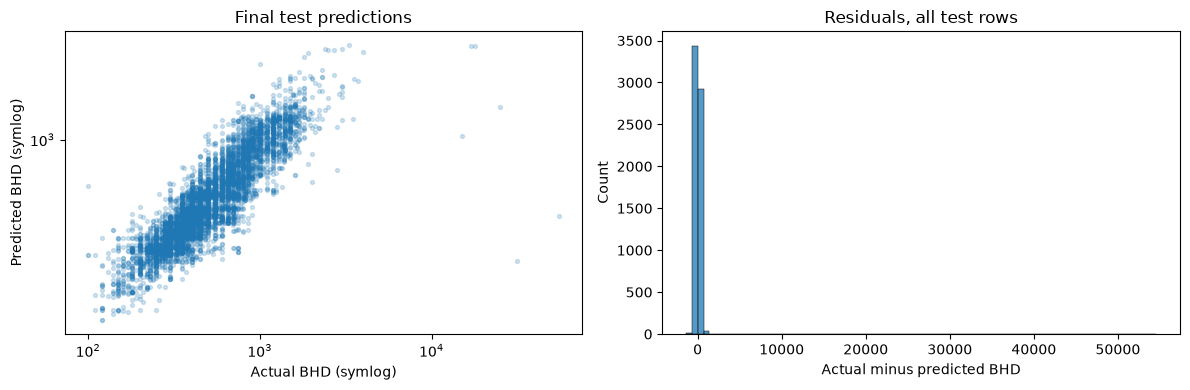

In [7]:
final_model=clone(candidates[winner_name]).fit(X.iloc[dev],y.iloc[dev])
test_pred=predict_nonnegative(final_model,X.iloc[test_idx])
baseline=np.repeat(y.iloc[dev].median(),len(test_idx))
test_mae=mean_absolute_error(y.iloc[test_idx],test_pred)
baseline_mae=mean_absolute_error(y.iloc[test_idx],baseline)
print(f'Final model: {winner_name}\nHoldout MAE: {test_mae:.3f} BHD\nMedian baseline MAE: {baseline_mae:.3f} BHD')
audit=pd.DataFrame({'Property_id':raw.iloc[test_idx].Property_id.to_numpy(),'actual':y.iloc[test_idx].to_numpy(),'predicted':test_pred,'property_type':X.iloc[test_idx].property_type.to_numpy(),'governorate':X.iloc[test_idx].governorate.to_numpy()})
audit['absolute_error']=abs(audit.actual-audit.predicted)
audit['rent_band']=pd.cut(audit.actual,[-np.inf,250,500,1000,2000,np.inf],labels=['<=250','250-500','500-1000','1000-2000','>2000'])
for col in ['property_type','governorate','rent_band']:
    display(audit.groupby(col,observed=True).agg(count=('absolute_error','size'),MAE=('absolute_error','mean')).round(2))
cut=y.iloc[dev].quantile(.99)
print('Diagnostic MAE for test rents <= development 99th percentile:',round(audit.loc[audit.actual<=cut,'absolute_error'].mean(),3),'BHD; cutoff:',cut)
display(audit.nlargest(10,'absolute_error'))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(audit.actual,audit.predicted,alpha=.2,s=8);axes[0].set_xscale('symlog');axes[0].set_yscale('symlog')
axes[0].set(xlabel='Actual BHD (symlog)',ylabel='Predicted BHD (symlog)',title='Final test predictions')
sns.histplot(audit.actual-audit.predicted,bins=80,ax=axes[1]);axes[1].set(title='Residuals, all test rows',xlabel='Actual minus predicted BHD')
plt.tight_layout();plt.show()
audit.to_csv(OUTPUT_DIR/'holdout_predictions.csv',index=False)
pd.DataFrame([{'model':winner_name,'holdout_MAE_BHD':test_mae,'median_baseline_MAE_BHD':baseline_mae,'fit_rows':len(train_idx),'validation_rows':len(val_idx),'holdout_rows':len(test_idx),'city_village_active':city_village_active}]).to_csv(OUTPUT_DIR/'evaluation_summary.csv',index=False)

## 6. Refit all labeled data and predict competition test
Competition labels are unavailable, so competition-test MAE is unknown. Refit the frozen choice on all labeled rows. The supplied sample expects `rent`, not the original notebook's `price`. Its numeric IDs do not match this test file's UUID IDs. Export predictions using actual test IDs; do not substitute sample IDs by row order without organizer confirmation.

In [8]:
production_model=clone(candidates[winner_name]).fit(X,y)
external_X=clean_features(external)
external_pred=predict_nonnegative(production_model,external_X)
assert len(external_pred)==len(external) and np.isfinite(external_pred).all()
predictions=pd.DataFrame({'Property_id':external.Property_id,'rent':external_pred})
predictions.to_csv(OUTPUT_DIR/'test_predictions_NEEDS_ID_CONFIRMATION.csv',index=False)
same_ids=len(sample)==len(external) and set(sample.Property_id.astype(str))==set(external.Property_id.astype(str))
print('Sample/test ID sets match:',same_ids)
display(pd.DataFrame({'sample_id':sample.Property_id.head().astype(str),'test_id':external.Property_id.head().astype(str)}))
print('Saved predictions; confirm organizer ID mapping before submission.')
display(predictions.head())

Sample/test ID sets match: False


,sample_id,test_id
0,4394,25c91c33-a523-42f2-8c10-9f340005471d
1,2338,6bcb7804-9cd7-4792-8cbe-abb4de65058a
2,8531,7b733e67-ec21-4427-95f8-4be3d9d18f6b
3,8952,feefd51f-a7d6-45b0-a9eb-200d9f9821b4
4,11064,cca286dd-ddc6-41c2-9584-f8e17461220f


Saved predictions; confirm organizer ID mapping before submission.


,Property_id,rent
0,25c91c33-a523-42f2-8c10-9f340005471d,450.722320
1,6bcb7804-9cd7-4792-8cbe-abb4de65058a,230.089858
2,7b733e67-ec21-4427-95f8-4be3d9d18f6b,1036.291755
3,feefd51f-a7d6-45b0-a9eb-200d9f9821b4,263.930012
4,cca286dd-ddc6-41c2-9584-f8e17461220f,451.975801


## Limitations / next iteration
1. Supply the trusted city/village mapping and rerun; preserve this no-mapping baseline. Unmapped locations remain missing, not village.
2. Confirm competition ID mapping with the organizer before uploading predictions.
3. Audit extreme rents/areas against source records. No verified correction, target-tail deletion or guessed period conversion was applied.
4. Missing furnishing/utilities and no agent evidence are explicit assumptions; source coverage can bias them.
5. Grouping prevents exact-feature/ID/URL overlap, but near-duplicate advertisements may remain. For predicting future listings, use a later-date grouped holdout.
6. Rare groups have little support. Natural apartment prevalence affects overall MAE; use subgroup counts to avoid unsupported claims. Do not apply classification SMOTE to rent.
7. No confidence interval or exhaustive search is claimed. Further tuning can use grouped cross-validation on development data with a fresh final test.